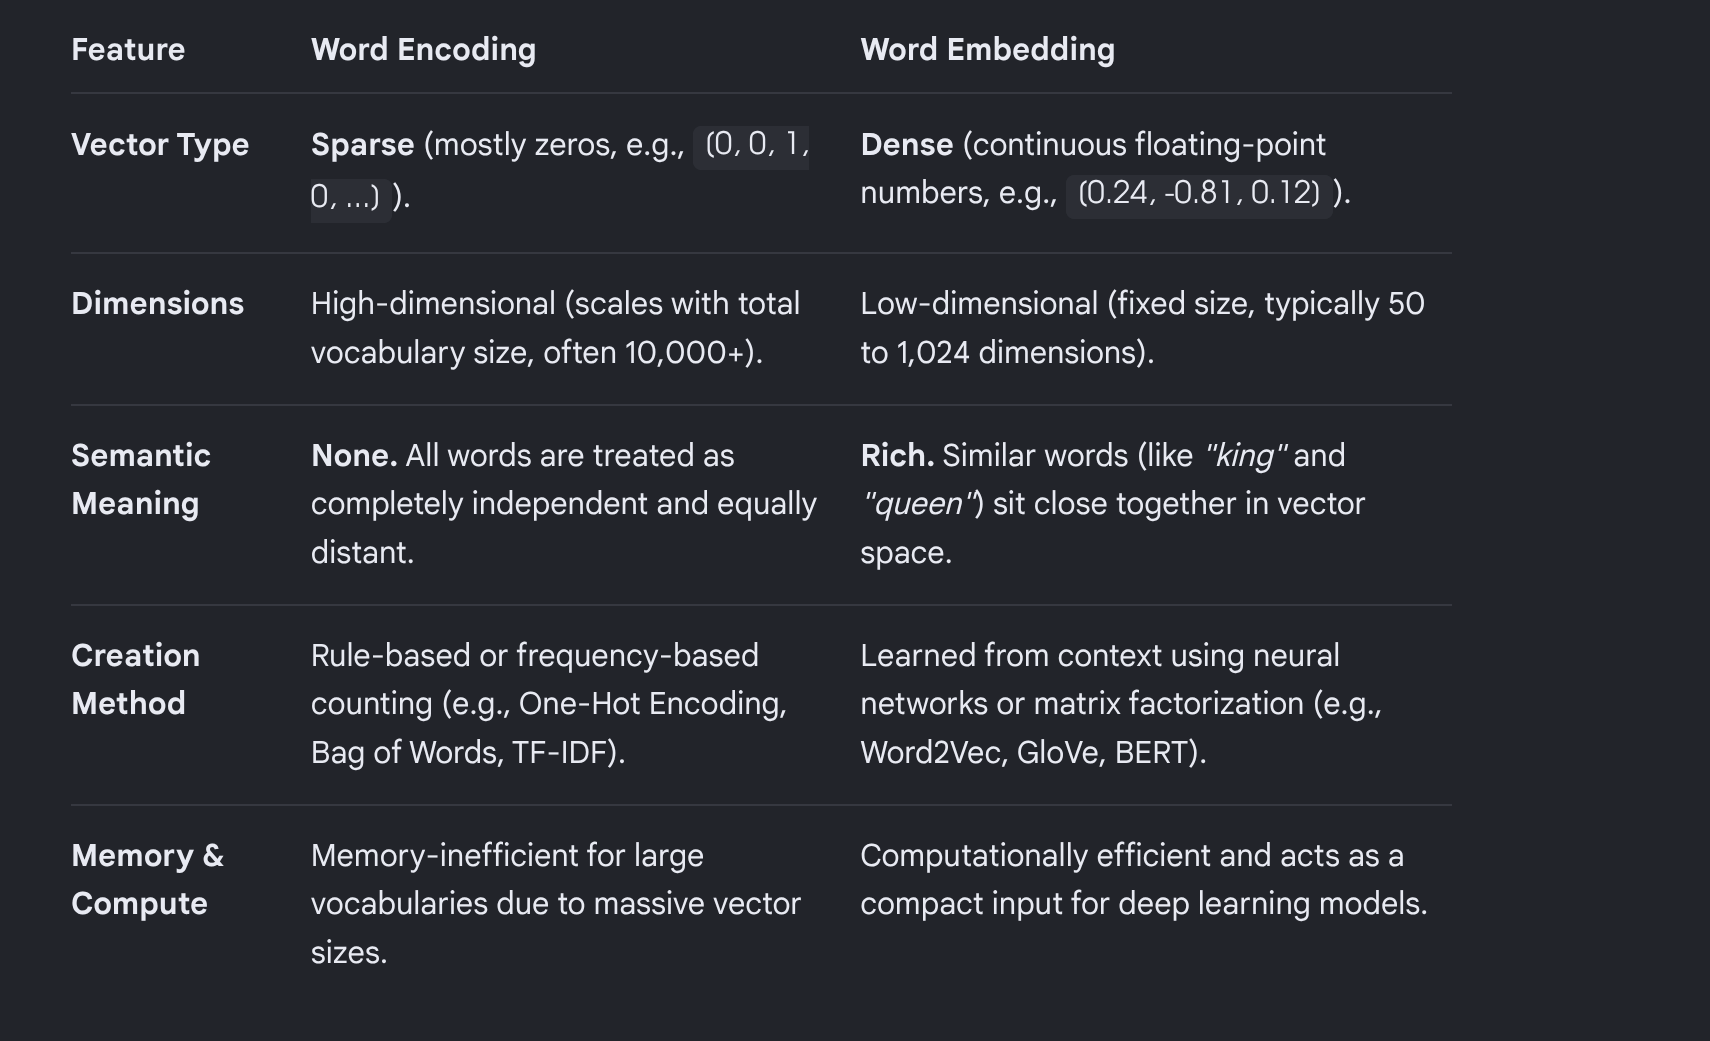

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from collections import OrderedDict

docs = ['go india',
        'india india',
        'hip hip hurray',
        'jeetega bhai jeetega india jeetega',
        'bharat mata ki jai',
        'kohli kohli',
        'sachin sachin',
        'dhoni dhoni',
        'modi ji ki jai',
        'inquilab zindabad']

## Tokenizer
Index 1 is reserved for the OOV token; real words start at 2 and are ordered by frequency (ties broken by first appearance)

In [2]:
class Tokenizer:
    def __init__(self, oov_token=None):
        self.oov_token = oov_token # if any given word is not present in the training data then that word would be replaced by oov(out of vocab)
        self.word_counts = OrderedDict()
        self.word_index = {}
        self.document_count = 0

     # fit_on_texts: It builds a vocabulary that gives every word a unique integer ID
     # so your text can be turned into numbers before going into the model.
    def fit_on_texts(self, texts):
        for text in texts:
            self.document_count += 1
            for w in text.lower().split():
                self.word_counts[w] = self.word_counts.get(w, 0) + 1
        # stable sort -> ties keep first-seen order (same as Keras)
        sorted_words = sorted(self.word_counts.items(), key=lambda kv: kv[1], reverse=True)
        vocab = [w for w, _ in sorted_words]
        if self.oov_token is not None:
            vocab = [self.oov_token] + vocab
        self.word_index = {w: i + 1 for i, w in enumerate(vocab)}


      # texts_to_sequences:It converts each sentence into a list of integer IDs, using the dictionary built by fit_on_texts.
      #For each word in each text:
        ##If the word is in word_index, it adds that word’s ID (e.g. india → 2).
        ##If the word is unknown, it adds the OOV ID (1) instead, as long as an OOV token was set. Without an OOV token, unknown words are silently dropped.
    def texts_to_sequences(self, texts):
        oov = self.word_index.get(self.oov_token)
        seqs = []
        for text in texts:
            seq = []
            for w in text.lower().split():
                if w in self.word_index:
                    seq.append(self.word_index[w])
                elif oov is not None:
                    seq.append(oov)
            seqs.append(seq)
        return seqs

# pad_sequences : It makes all sequences the same length by padding short ones with zeros and cutting long ones,
# so they can be stacked into one array for the model
   def pad_sequences(sequences, maxlen=None, padding='pre', truncating='pre', value=0):
        """Equivalent of keras.utils.pad_sequences (returns int32 array)."""
        if maxlen is None:
            maxlen = max(len(s) for s in sequences)
        out = np.full((len(sequences), maxlen), value, dtype=np.int32)
        for i, s in enumerate(sequences):
            if len(s) == 0:
                continue
            s = s[-maxlen:] if truncating == 'pre' else s[:maxlen]
            if padding == 'post':
                out[i, :len(s)] = s
            else:
                out[i, -len(s):] = s
        return out

In [3]:
tokenizer = Tokenizer(oov_token='<nothing>')

In [4]:
tokenizer.fit_on_texts(docs)

In [5]:
tokenizer.word_index # tells what idx are defined to the unique words

{'<nothing>': 1,
 'india': 2,
 'jeetega': 3,
 'hip': 4,
 'ki': 5,
 'jai': 6,
 'kohli': 7,
 'sachin': 8,
 'dhoni': 9,
 'go': 10,
 'hurray': 11,
 'bhai': 12,
 'bharat': 13,
 'mata': 14,
 'modi': 15,
 'ji': 16,
 'inquilab': 17,
 'zindabad': 18}

In [6]:
tokenizer.word_counts # frequency of each word

OrderedDict([('go', 1),
             ('india', 4),
             ('hip', 2),
             ('hurray', 1),
             ('jeetega', 3),
             ('bhai', 1),
             ('bharat', 1),
             ('mata', 1),
             ('ki', 2),
             ('jai', 2),
             ('kohli', 2),
             ('sachin', 2),
             ('dhoni', 2),
             ('modi', 1),
             ('ji', 1),
             ('inquilab', 1),
             ('zindabad', 1)])

In [7]:
tokenizer.document_count # number of sentences

10

In [8]:
sequences = tokenizer.texts_to_sequences(docs)
sequences

[[10, 2],
 [2, 2],
 [4, 4, 11],
 [3, 12, 3, 2, 3],
 [13, 14, 5, 6],
 [7, 7],
 [8, 8],
 [9, 9],
 [15, 16, 5, 6],
 [17, 18]]

In [11]:
sequences = Tokenizer.pad_sequences(sequences, padding='post')

In [12]:
sequences

array([[10,  2,  0,  0,  0],
       [ 2,  2,  0,  0,  0],
       [ 4,  4, 11,  0,  0],
       [ 3, 12,  3,  2,  3],
       [13, 14,  5,  6,  0],
       [ 7,  7,  0,  0,  0],
       [ 8,  8,  0,  0,  0],
       [ 9,  9,  0,  0,  0],
       [15, 16,  5,  6,  0],
       [17, 18,  0,  0,  0]], dtype=int32)

## IMDB dataset
Keras' `imdb.load_data()` downloads an `.npz` file and offsets the word indices (`start_char=1`, `oov_char=2`, `index_from=3`). We do the same without Keras.

In [13]:
import os, urllib.request

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/imdb.npz"
path = "imdb.npz"
if not os.path.exists(path):
    urllib.request.urlretrieve(url, path)

def load_imdb(path, start_char=1, index_from=3):
    with np.load(path, allow_pickle=True) as f:
        x_train, y_train = f["x_train"], f["y_train"]
        x_test, y_test = f["x_test"], f["y_test"]
    add = lambda xs: [[start_char] + [w + index_from for w in x] for x in xs]
    return (add(x_train), y_train), (add(x_test), y_test)

(X_train, y_train), (X_test, y_test) = load_imdb(path)

In [14]:
len(X_train)

25000

In [16]:
len(X_train[0])

2494

In [17]:
len(X_train[0])

2494

In [18]:
len(X_train[2])

2494

In [19]:
X_train = Tokenizer.pad_sequences(X_train, padding='post')
X_test = Tokenizer.pad_sequences(X_test, padding='post')

In [20]:
X_train[0]

array([    1, 23025,   312, ...,     0,     0,     0],
      shape=(2494,), dtype=int32)

In [21]:
len(X_train[0])

2494

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# largest word ID in the data + 1
vocab_size = int(max(X_train.max(), X_test.max())) + 1

class SimpleRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_size=32):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_size, nonlinearity='tanh', batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):                   # x: (batch, 50) integer IDs
        x = self.embedding(x)               # (batch, 50, embed_dim)
        _, h_n = self.rnn(x)                # h_n: (1, batch, 32) -> last time step only
        return self.fc(h_n[-1]).squeeze(1)  # logits, shape (batch,)

model = SimpleRNNClassifier(vocab_size).to(device)
print(model)
print("Total params:", sum(p.numel() for p in model.parameters()))

SimpleRNNClassifier(
  (embedding): Embedding(88588, 32, padding_idx=0)
  (rnn): RNN(32, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Total params: 2836961


In [23]:
# This turns your NumPy arrays into PyTorch tensors and sets up loaders that feed the model data in small batches
def to_dataset(X, y):
    X = torch.tensor(X, dtype=torch.long)          # (N, 50) integer IDs
    y = torch.tensor(np.asarray(y), dtype=torch.float32)
    return TensorDataset(X, y)

train_loader = DataLoader(to_dataset(X_train, y_train), batch_size=32, shuffle=True)
test_loader = DataLoader(to_dataset(X_test, y_test), batch_size=32)

## Training

In [24]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
epochs = 5
for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(test_loader, False)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    print(f"Epoch {epoch}/{epochs} - loss: {tr_loss:.4f} - accuracy: {tr_acc:.4f} "
          f"- val_loss: {va_loss:.4f} - val_accuracy: {va_acc:.4f}")

Epoch 1/5 - loss: 0.6935 - accuracy: 0.5015 - val_loss: 0.6938 - val_accuracy: 0.5000
Epoch 2/5 - loss: 0.6933 - accuracy: 0.4990 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 3/5 - loss: 0.6933 - accuracy: 0.4907 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 4/5 - loss: 0.6933 - accuracy: 0.4918 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 5/5 - loss: 0.6932 - accuracy: 0.5002 - val_loss: 0.6934 - val_accuracy: 0.5000


## Prediction
Probabilities (what the Keras sigmoid output would give).

In [26]:
model.eval()
with torch.no_grad():
    sample = torch.tensor(X_test[:5], dtype=torch.long).to(device)
    logits = model(sample)
    probs = torch.sigmoid(logits)
print("Predicted probabilities:", probs.cpu().numpy())
print("True labels:", y_test[:5])

Predicted probabilities: [0.510365 0.510365 0.510365 0.510365 0.510365]
True labels: [1 1 1 1 1]


### Fixing the Accuracy: Using a GRU with Maxlen = 200 & Global Average Pooling

Let's apply the improvements discussed:
1. Limit sequence length to `200` (reviews are generally understood within the first/last few hundred words).
2. Use a `nn.GRU` instead of vanilla `nn.RNN` to prevent vanishing gradients.
3. Perform global average pooling over the sequence dimensions to capture context from the entire sentence.

In [30]:
# 1. Reload original unpadded IMDB sequences to get rid of the 2494 length zero-padding
(X_train_raw, y_train), (X_test_raw, y_test) = load_imdb(path)

# 2. Limit the sequence length to 200 on unpadded raw sequences
MAX_LEN = 200
X_train_short = Tokenizer.pad_sequences(X_train_raw, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_short = Tokenizer.pad_sequences(X_test_raw, maxlen=MAX_LEN, padding='post', truncating='post')

# Recreate data loaders with the correct non-zero sequences
train_loader_improved = DataLoader(to_dataset(X_train_short, y_train), batch_size=64, shuffle=True)
test_loader_improved = DataLoader(to_dataset(X_test_short, y_test), batch_size=64)

# 3. Define the improved architecture using GRU and Global Pooling
class ImprovedClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_size=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_size, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, 1)

    def forward(self, x):
        x = self.embedding(x)
        out, _ = self.gru(x)
        out = torch.mean(out, dim=1)
        return self.fc(out).squeeze(1)

improved_model = ImprovedClassifier(vocab_size).to(device)
print("First sample check (should not be all zeros):")
print(X_train_short[0][:20])
print(improved_model)

First sample check (should not be all zeros):
[    1 23025   312     9     6  1072   212    12  2178    33     4   172
    58    17    49    85  5872    44   396   113]
ImprovedClassifier(
  (embedding): Embedding(88588, 64, padding_idx=0)
  (gru): GRU(64, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [32]:
# Train the improved model on the newly fixed non-zero sequences
opt = torch.optim.Adam(improved_model.parameters(), lr=1e-3)

def run_epoch_improved(loader, train):
    improved_model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = improved_model(xb)
            loss = criterion(logits, yb)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            total_loss += loss.item() * len(yb)
            correct += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

for epoch in range(1, 4):
    tr_loss, tr_acc = run_epoch_improved(train_loader_improved, True)
    va_loss, va_acc = run_epoch_improved(test_loader_improved, False)
    print(f"Epoch {epoch}/3 - loss: {tr_loss:.4f} - accuracy: {tr_acc:.4f} - val_loss: {va_loss:.4f} - val_accuracy: {va_acc:.4f}")

Epoch 1/3 - loss: 0.2029 - accuracy: 0.9242 - val_loss: 0.3848 - val_accuracy: 0.8404
Epoch 2/3 - loss: 0.1514 - accuracy: 0.9452 - val_loss: 0.4539 - val_accuracy: 0.8367
Epoch 3/3 - loss: 0.1060 - accuracy: 0.9634 - val_loss: 0.4787 - val_accuracy: 0.8339
